# 01 — Dataset Exploration

## Objective

Explore the Airbus Ship Detection dataset before developing
self-supervised representation-learning methods.

We will:

- Inspect the dataset structure and annotation format.
- Analyze ship-containing and empty images.
- Visualize satellite imagery and segmentation masks.
- Investigate ship distribution and image characteristics.
- Record observations that may influence model design.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

In [2]:
# Project and dataset paths
PROJECT_ROOT = Path.cwd()

# If the notebook is launched from another directory, locate the project
# root.
if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = Path("../").resolve()

DATASET_DIR = PROJECT_ROOT / "raw" / "airbus-ship-detection"
TRAIN_DIR = DATASET_DIR / "train_v2"
ANNOTATION_FILE = DATASET_DIR / "train_ship_segmentations_v2.csv"

print(f"Project root: {PROJECT_ROOT.resolve()}")
print(f"Training directory exists: {TRAIN_DIR.is_dir()}")
print(f"Annotation file exists: {ANNOTATION_FILE.is_file()}")

Project root: /home/abhi/Dev/varuna-ssl
Training directory exists: True
Annotation file exists: True


In [3]:
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["image.cmap"] = "gray"

In [4]:
annotations = pd.read_csv(ANNOTATION_FILE)

print(f"Annotation rows: {len(annotations):,}")
print(f"Unique image IDs: {annotations['ImageId'].nunique():,}")

annotations.head()


Annotation rows: 231,723
Unique image IDs: 192,556


,ImageId,EncodedPixels
0,00003e153.jpg,NaN
1,0001124c7.jpg,NaN
2,000155de5.jpg,264661 17 265429 33 266197 33 266965 33 267733...
3,000194a2d.jpg,360486 1 361252 4 362019 5 362785 8 363552 10 ...
4,000194a2d.jpg,51834 9 52602 9 53370 9 54138 9 54906 9 55674 ...


In [5]:
annotations.info()

print("\nMissing values:")
display(annotations.isna().sum())

print("\nDuplicate rows:")
print(annotations.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 231723 entries, 0 to 231722
Data columns (total 2 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   ImageId        231723 non-null  str  
 1   EncodedPixels  81723 non-null   str  
dtypes: str(2)
memory usage: 3.5 MB

Missing values:


ImageId               0
EncodedPixels    150000
dtype: int64


Duplicate rows:
0


In [6]:
annotations["has_ship"] = (
    annotations["EncodedPixels"].fillna("").str.strip().ne("")
)

image_summary = annotations.groupby("ImageId", as_index=False).agg(
    has_ship=("has_ship", "any"),
    annotation_rows=("EncodedPixels", "size"),
    ship_masks=("has_ship", "sum"),
)


In [7]:
print(f"Unique images: {len(image_summary):,}")
print(f"Images containing ships: {image_summary['has_ship'].sum():,}")
print(f"Images without ships: {(~image_summary['has_ship']).sum():,}")
print(
    f"Images with multiple annotation rows: "
    f"{(image_summary['annotation_rows'] > 1).sum():,}"
)

image_summary.head()

Unique images: 192,556
Images containing ships: 42,556
Images without ships: 150,000
Images with multiple annotation rows: 15,452


,ImageId,has_ship,annotation_rows,ship_masks
0,00003e153.jpg,False,1,0
1,0001124c7.jpg,False,1,0
2,000155de5.jpg,True,1,1
3,000194a2d.jpg,True,5,5
4,0001b1832.jpg,False,1,0


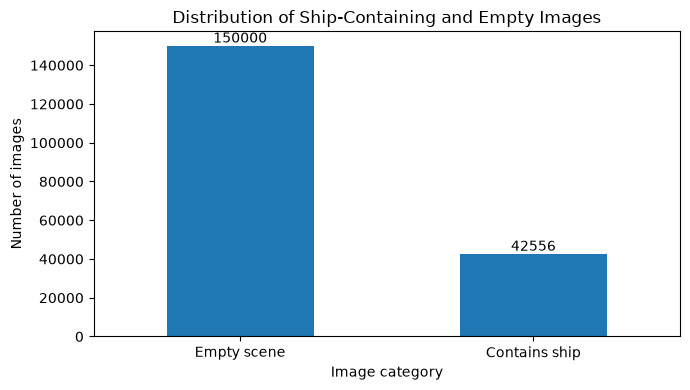

In [8]:
counts = (
    image_summary["has_ship"]
    .value_counts()
    .rename(index={True: "Contains ship", False: "Empty scene"})
)

ax = counts.plot(kind="bar", rot=0, figsize=(7, 4))
ax.set_title("Distribution of Ship-Containing and Empty Images")
ax.set_xlabel("Image category")
ax.set_ylabel("Number of images")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()


## 2. Visual Inspection of Satellite Images

We inspect ship-containing and empty scenes to understand the
visual characteristics of the dataset, including ship scale,
ocean texture, coastlines, and background variation.


In [9]:
import random

random.seed(42)

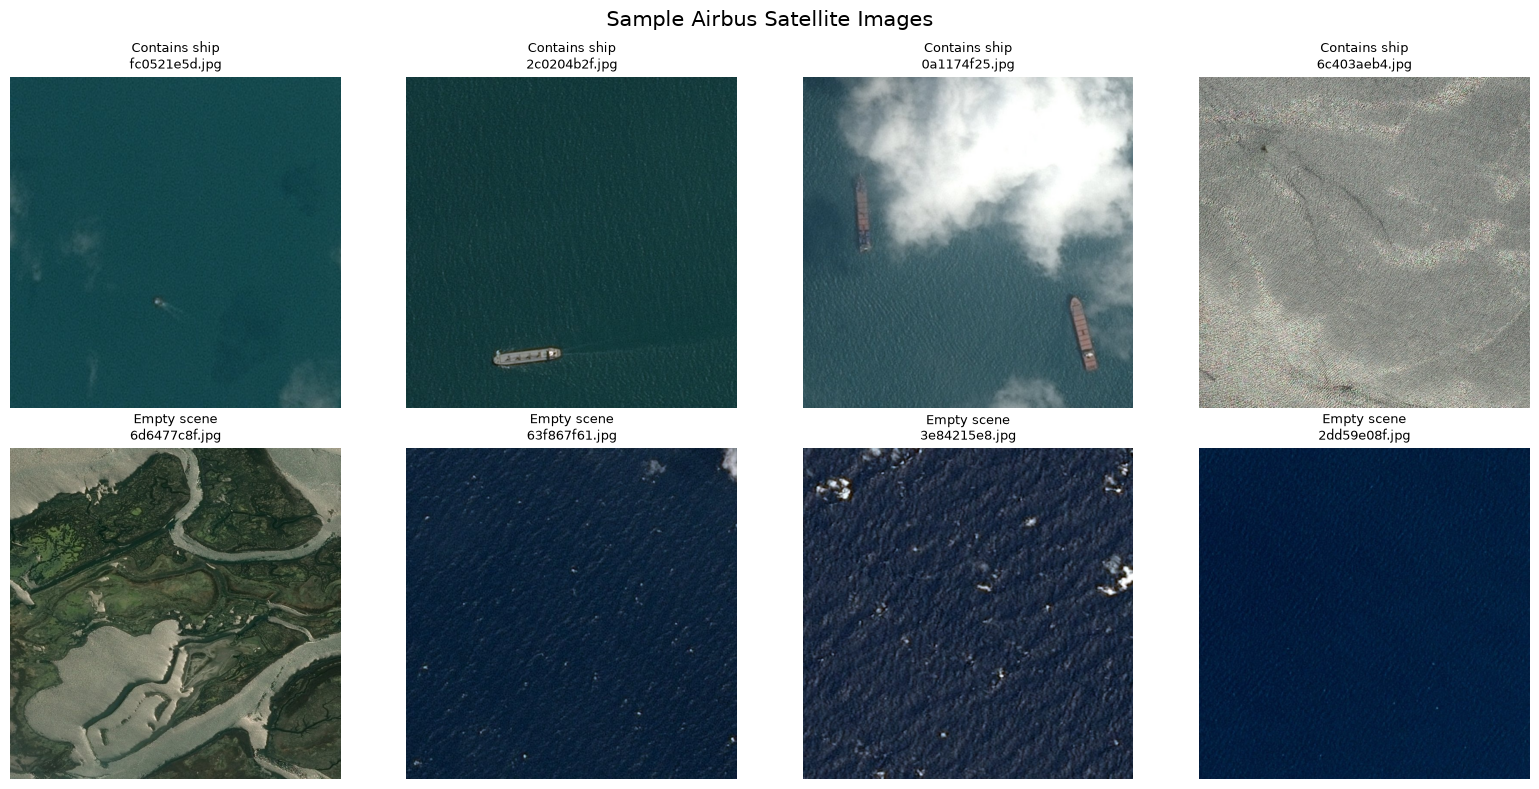

In [10]:
ship_ids = image_summary.loc[image_summary["has_ship"], "ImageId"].tolist()

empty_ids = image_summary.loc[~image_summary["has_ship"], "ImageId"].tolist()

sample_ids = random.sample(ship_ids, 4) + random.sample(empty_ids, 4)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, image_id in zip(axes.flat, sample_ids):
    image_path = TRAIN_DIR / image_id

    with Image.open(image_path) as image:
        ax.imshow(image)

    category = "Contains ship" if image_id in ship_ids else "Empty scene"

    ax.set_title(f"{category}\n{image_id}", fontsize=9)
    ax.axis("off")

plt.suptitle("Sample Airbus Satellite Images", fontsize=15)
plt.tight_layout()
plt.show()


## 3. Run-Length Encoded Segmentation Masks

The annotation CSV represents ship masks using run-length encoding.
We decode these values into binary masks and overlay them on the
original satellite images.


In [11]:
def decode_rle(encoded_pixels, height=768, width=768):
    """Decode an Airbus RLE string into a binary mask."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(encoded_pixels) or not str(encoded_pixels).strip():
        return mask.reshape((height, width))

    values = np.asarray(encoded_pixels.split(), dtype=np.int64)

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    for start, end in zip(starts, ends):
        if start < 0 or end > height * width:
            raise ValueError("RLE run is outside the image bounds")

    for start, end in zip(starts, ends):
        mask[start:end] = 1

    # Airbus RLE uses column-major ordering.
    return mask.reshape((width, height)).T

In [12]:
def get_image_annotations(image_id):
    return annotations.loc[
        annotations["ImageId"] == image_id, "EncodedPixels"
    ].dropna()


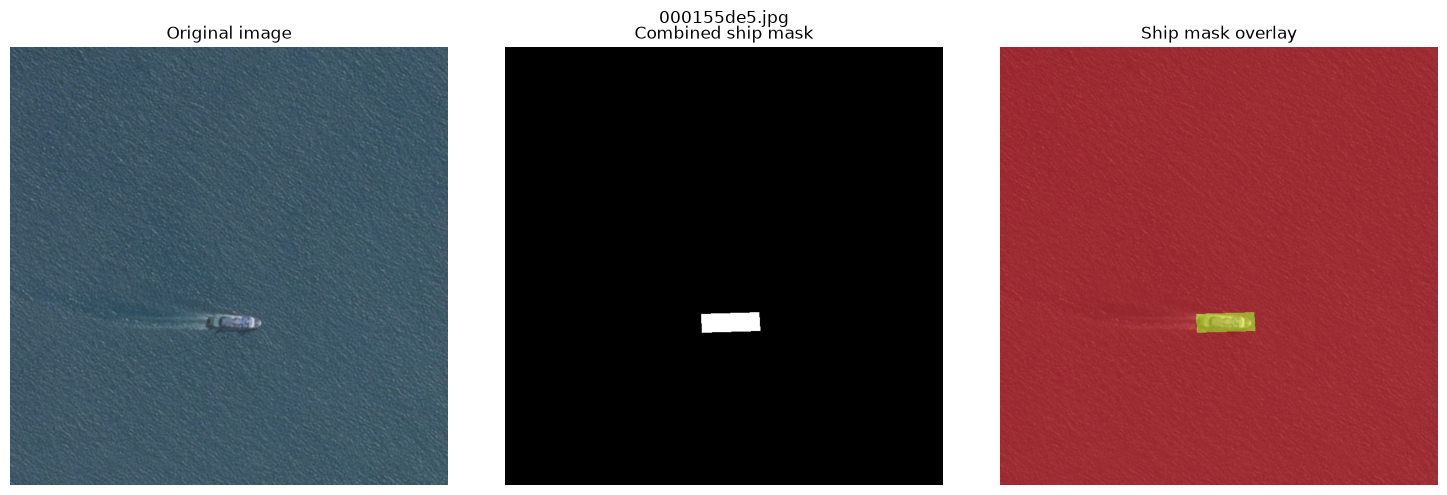

In [13]:
def visualize_mask(image_id):
    image_path = TRAIN_DIR / image_id

    with Image.open(image_path) as image:
        image = np.asarray(image.convert("RGB"))

    mask = np.zeros(image.shape[:2], dtype=np.uint8)

    for encoded_pixels in get_image_annotations(image_id):
        mask |= decode_rle(encoded_pixels)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image)
    axes[0].set_title("Original image")

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Combined ship mask")

    axes[2].imshow(image)
    axes[2].imshow(mask, alpha=0.5, cmap="autumn", vmin=0, vmax=1)
    axes[2].set_title("Ship mask overlay")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(image_id)
    plt.tight_layout()
    plt.show()


visualize_mask(ship_ids[0])


## 4. Ship Size and Distribution Analysis

We measure the number of annotated ships per image and the
fraction of image pixels occupied by ship masks.

These measurements help us understand the dataset's visual
characteristics and choose appropriate image augmentations.


In [14]:
ship_annotations = annotations.loc[
    annotations["EncodedPixels"].fillna("").str.strip().ne("")
].copy()

ship_annotations["mask_pixels"] = ship_annotations["EncodedPixels"].map(
    lambda rle: int(np.asarray(rle.split()[1::2], dtype=np.int64).sum())
)

print(f"Total ship masks: {len(ship_annotations):,}")
print("\nShip-mask pixel count statistics:")
display(
    ship_annotations["mask_pixels"].describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

Total ship masks: 81,723

Ship-mask pixel count statistics:


count    81723.000000
mean      1567.402849
std       2842.081203
min          2.000000
25%        111.000000
50%        408.000000
75%       1550.000000
90%       4872.000000
95%       7521.000000
99%      14942.000000
max      25904.000000
Name: mask_pixels, dtype: float64

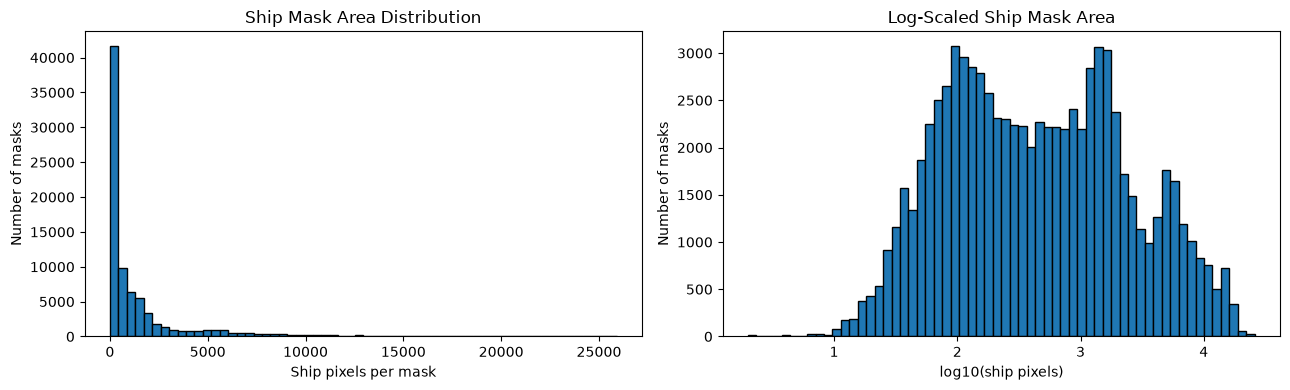

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(ship_annotations["mask_pixels"], bins=60, edgecolor="black")
axes[0].set_title("Ship Mask Area Distribution")
axes[0].set_xlabel("Ship pixels per mask")
axes[0].set_ylabel("Number of masks")

axes[1].hist(
    np.log10(ship_annotations["mask_pixels"].clip(lower=1)),
    bins=60,
    edgecolor="black",
)
axes[1].set_title("Log-Scaled Ship Mask Area")
axes[1].set_xlabel("log10(ship pixels)")
axes[1].set_ylabel("Number of masks")

plt.tight_layout()
plt.show()


In [16]:
IMAGE_PIXELS = 768 * 768

ship_annotations["mask_fraction"] = (
    ship_annotations["mask_pixels"] / IMAGE_PIXELS
)

(ship_annotations["mask_fraction"] * 100).describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).rename("mask_area_percent")

count    81723.000000
mean         0.265741
std          0.481852
min          0.000339
25%          0.018819
50%          0.069173
75%          0.262790
90%          0.826009
95%          1.275126
99%          2.533298
max          4.391819
Name: mask_area_percent, dtype: float64

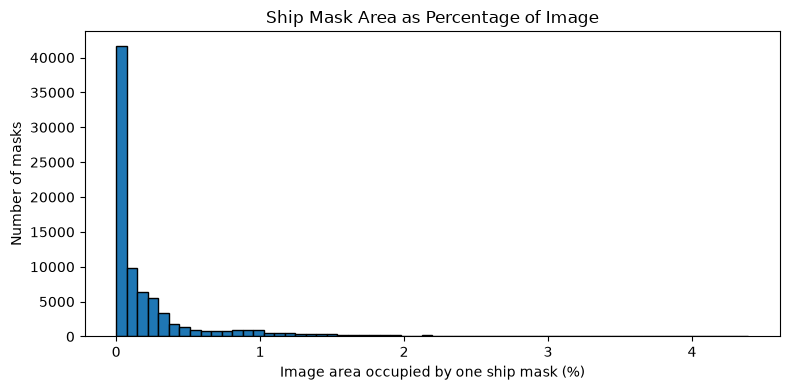

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    ship_annotations["mask_fraction"] * 100,
    bins=60,
    edgecolor="black",
)

ax.set_title("Ship Mask Area as Percentage of Image")
ax.set_xlabel("Image area occupied by one ship mask (%)")
ax.set_ylabel("Number of masks")

plt.tight_layout()
plt.show()

In [18]:
percentiles = [0, 25, 50, 75, 90, 95, 99, 100]

# Sort individual ship annotations by mask area.
sorted_masks = ship_annotations.sort_values("mask_pixels").reset_index(
    drop=True
)

In [19]:
# Select the mask closest to each requested percentile.
selected = []

for percentile in percentiles:
    position = round((percentile / 100) * (len(sorted_masks) - 1))
    row = sorted_masks.iloc[position]

    selected.append(
        {
            "percentile": percentile,
            "image_id": row["ImageId"],
            "mask_pixels": int(row["mask_pixels"]),
            "mask_fraction": float(row["mask_fraction"]),
            "encoded_pixels": row["EncodedPixels"],
        }
    )

P  0: dd38da47f.jpg, 2 pixels, 0.000% of image
P 25: 9b564c9c4.jpg, 111 pixels, 0.000% of image
P 50: 4a5a9a20f.jpg, 408 pixels, 0.001% of image
P 75: be9aee541.jpg, 1,550 pixels, 0.003% of image
P 90: 22d4b464d.jpg, 4,872 pixels, 0.008% of image
P 95: 698f27d5f.jpg, 7,521 pixels, 0.013% of image
P 99: 26d4fdfa3.jpg, 14,942 pixels, 0.025% of image
P100: a129c36b3.jpg, 25,904 pixels, 0.044% of image


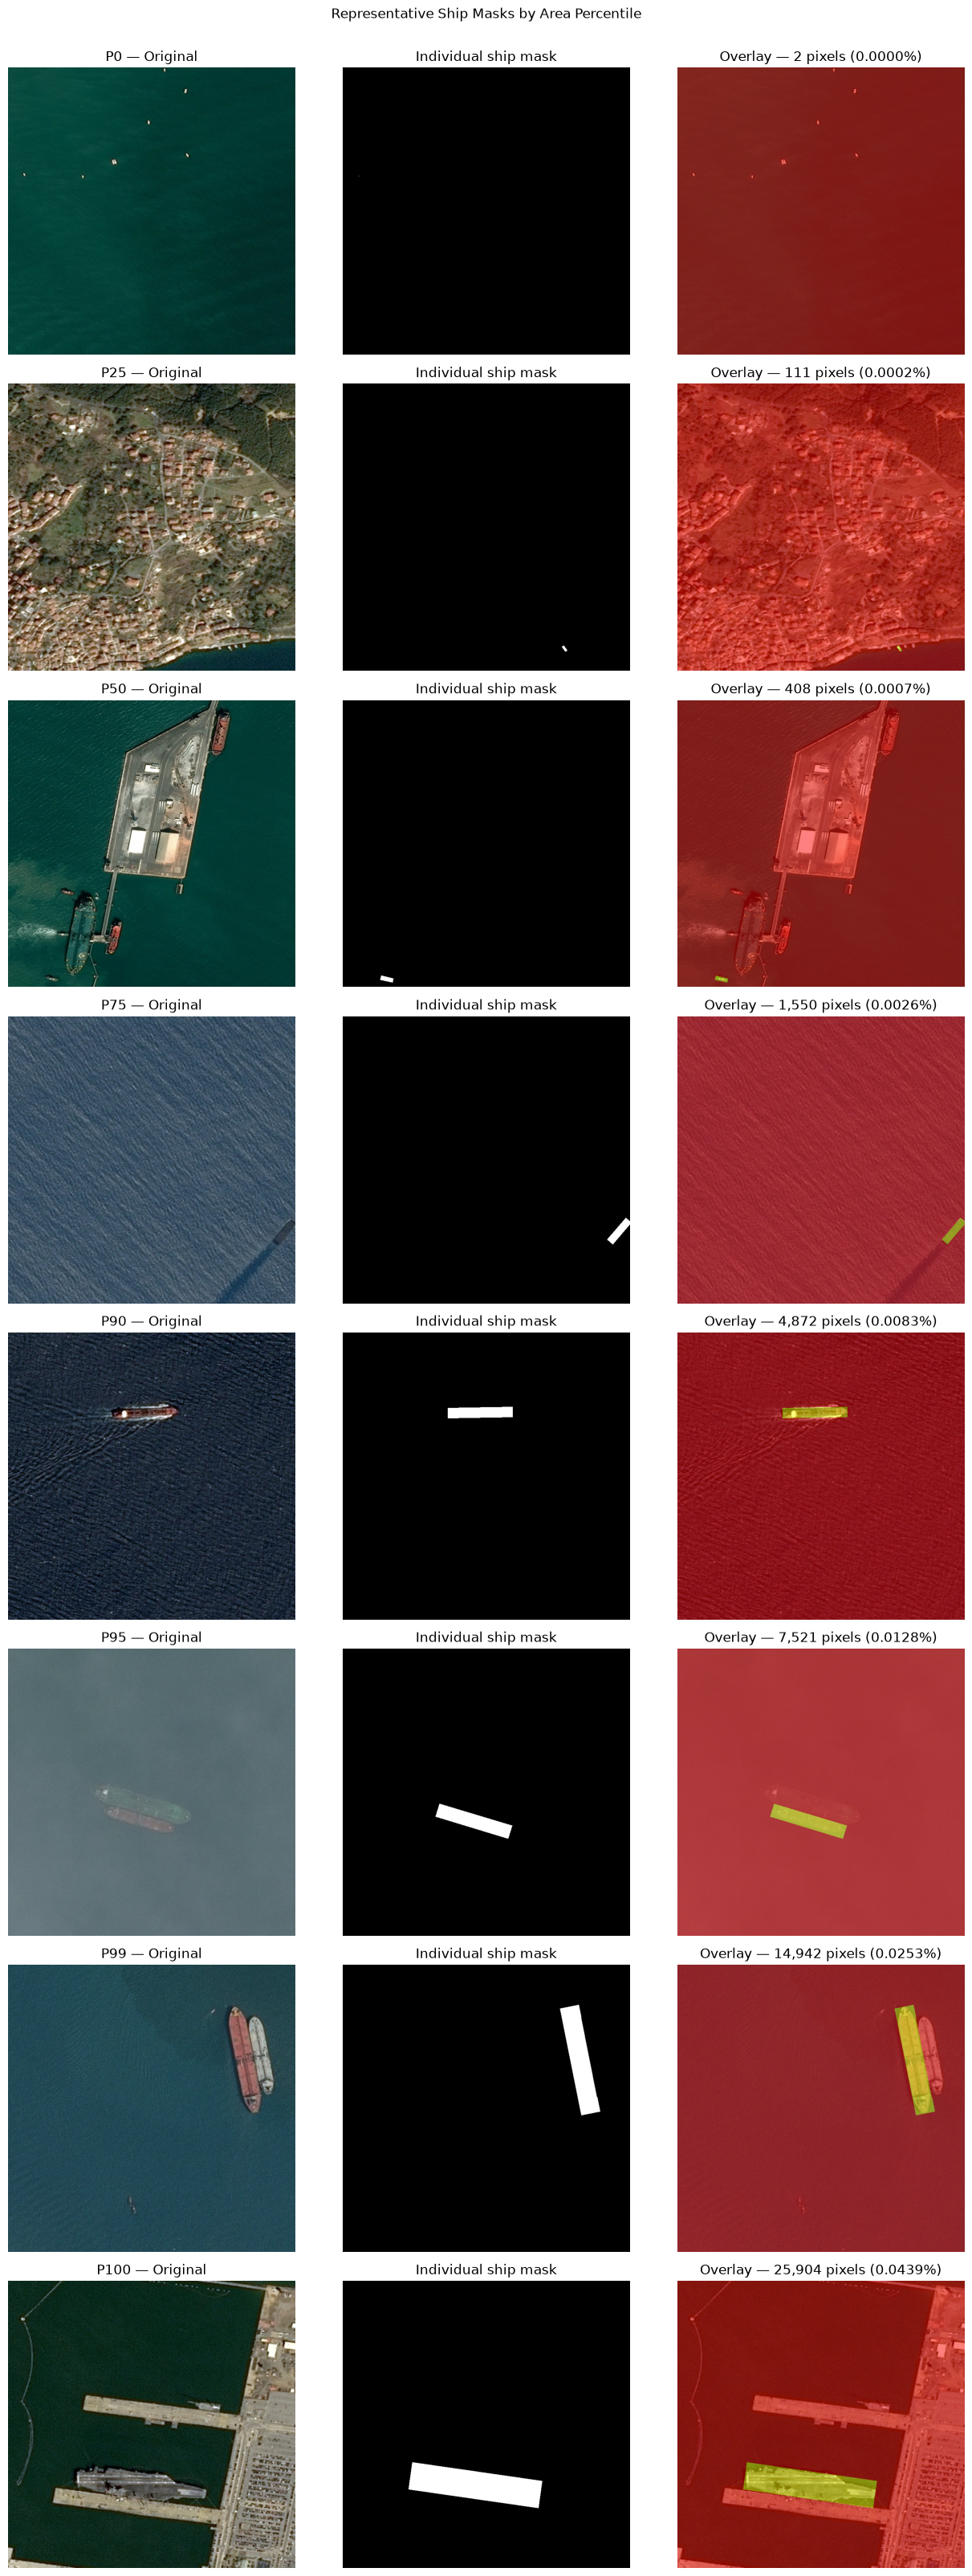

In [20]:
# Plot original image, individual mask, and overlay.
fig, axes = plt.subplots(len(selected), 3, figsize=(13, 4 * len(selected)))

for i, item in enumerate(selected):
    image_id = item["image_id"]

    with Image.open(TRAIN_DIR / image_id) as image:
        image = np.asarray(image.convert("RGB"))

    mask = decode_rle(item["encoded_pixels"])

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"P{item['percentile']} — Original")

    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Individual ship mask")

    axes[i, 2].imshow(image)
    axes[i, 2].imshow(mask, alpha=0.5, cmap="autumn", vmin=0, vmax=1)
    axes[i, 2].set_title(
        f"Overlay — {item['mask_pixels']:,} pixels "
        f"({item['mask_fraction']:.4f}%)"
    )

    for ax in axes[i]:
        ax.axis("off")

    print(
        f"P{item['percentile']:>3}: {image_id}, "
        f"{item['mask_pixels']:,} pixels, "
        f"{item['mask_fraction']:.3f}% of image"
    )

plt.suptitle("Representative Ship Masks by Area Percentile", y=1.002)
plt.tight_layout()
plt.show()
